<a href="https://colab.research.google.com/github/yashkeswani29-cpu/E-commerce-site-A-B-testing-and-Statistical-Analysis/blob/main/Statistical_Analysis_A_B_testing_and_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 Probability

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
%matplotlib inline
random.seed(42)

In [2]:
df = pd.read_csv('ab_data.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [3]:
df.shape

(294478, 5)

In [4]:
df.nunique()

,0
user_id,290584
timestamp,294478
group,2
landing_page,2
converted,2


proportion of user converted

In [5]:
df['converted'].value_counts()[1] / (df['converted'].value_counts()[0] + df['converted'].value_counts()[1])

np.float64(0.11965919355605512)

In [6]:
df.query("group == 'treatment' and landing_page != 'new_page'").count()[0] + \
df.query("group != 'treatment' and landing_page == 'new_page'").count()[0]

/tmp/ipykernel_1757/3540755905.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df.query("group == 'treatment' and landing_page != 'new_page'").count()[0] + \
/tmp/ipykernel_1757/3540755905.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df.query("group != 'treatment' and landing_page == 'new_page'").count()[0]


np.int64(3893)

3893 no of times treatment and new page don't line up

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [8]:
df.drop(df.query("group == 'treatment' and landing_page != 'new_page'").index, inplace = True)
df.drop(df.query("group != 'treatment' and landing_page == 'new_page'").index, inplace = True)
df2 = df
df2.shape

(290585, 5)

In [9]:
df2[((df2['group'] == 'treatment') == (df2['landing_page'] == 'new_page')) == False].shape[0]

0

In [10]:
df2.nunique()

,0
user_id,290584
timestamp,290585
group,2
landing_page,2
converted,2


finding duplicate

In [11]:
df2[df2['user_id'].duplicated()]

,user_id,timestamp,group,landing_page,converted
2893,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


In [12]:
duplicate = df2[df2['user_id'].duplicated()]

In [13]:
df2.drop(duplicate.index, inplace = True)

In [14]:
df2.nunique()

,0
user_id,290584
timestamp,290584
group,2
landing_page,2
converted,2


In [15]:
df2[df2['converted'] == 1].count()[4] / df2['converted'].count()

/tmp/ipykernel_1757/3917321916.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df2[df2['converted'] == 1].count()[4] / df2['converted'].count()


np.float64(0.11959708724499628)

0.11959708724499628. probablity

In [16]:
control = df2.query("group == 'control' and converted == 1").count()[4] / df2[df2['group'] == 'control'].count()[4]
control

/tmp/ipykernel_1757/2814310423.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  control = df2.query("group == 'control' and converted == 1").count()[4] / df2[df2['group'] == 'control'].count()[4]
/tmp/ipykernel_1757/2814310423.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  control = df2.query("group == 'control' and converted == 1").count()[4] / df2[df2['group'] == 'control'].count()[4]


np.float64(0.1203863045004612)

0.1203863045004612. probability converted in the control group

In [17]:
treatment = df2.query("group == 'treatment' and converted == 1").count()[4] / df2[df2['group'] == 'treatment'].count()[4]
treatment

/tmp/ipykernel_1757/1174017357.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  treatment = df2.query("group == 'treatment' and converted == 1").count()[4] / df2[df2['group'] == 'treatment'].count()[4]
/tmp/ipykernel_1757/1174017357.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  treatment = df2.query("group == 'treatment' and converted == 1").count()[4] / df2[df2['group'] == 'treatment'].count()[4]


np.float64(0.11880806551510564)

0.11880806551510564 probability converted in the treatment group

In [18]:

df2.query("landing_page == 'new_page'").count()[3] / df2['landing_page'].count()

/tmp/ipykernel_1757/633221035.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df2.query("landing_page == 'new_page'").count()[3] / df2['landing_page'].count()


np.float64(0.5000619442226688)

0.5000619442226688 probability received the new page

**I believe this experimemt design is robust and persuasive with following reasons.**

1.From above results, there are at least 50% of users willing to land new pages.

2.Although only around 11.96% of users convert to new version, the result is still acceptable for me.

3.In addition, the probability of an individual received the new page in either "control" or "treatment" groups are around 12% which means not only the size of both groups are similar but the conversion rates are close.

# Part 2 A/B Test

Pold - Pnew >= 0
Pold - Pnew < 0

In [19]:
p_new = df2.query("converted == 1").count()[4]/ df2["converted"].count()
p_new

/tmp/ipykernel_1757/119957928.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_new = df2.query("converted == 1").count()[4]/ df2["converted"].count()


np.float64(0.11959708724499628)

0.11959708724499628

In [20]:
p_old = df2.query("converted == 1").count()[4]/ df2["converted"].count()
p_old

/tmp/ipykernel_1757/3407225112.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_old = df2.query("converted == 1").count()[4]/ df2["converted"].count()


np.float64(0.11959708724499628)

0.11959708724499628

In [21]:
n_new = df2.query('group == "treatment"').count()[0]
n_new

/tmp/ipykernel_1757/2594878698.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  n_new = df2.query('group == "treatment"').count()[0]


np.int64(145310)

145310

In [22]:
n_old = df2.query('group == "control"').count()[0]
n_old

/tmp/ipykernel_1757/853391046.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  n_old = df2.query('group == "control"').count()[0]


np.int64(145274)

145274

In [23]:
p_dif = p_new - p_old
p_dif

np.float64(0.0)

In [24]:
new_page_converted = np.random.choice([0,1], n_new, p=(p_new, 1-p_new))
new_page_converted

array([1, 1, 1, ..., 1, 1, 0])

In [25]:
old_page_converted = np.random.choice([0,1], n_old, p=(p_old, 1-p_old))
old_page_converted

array([1, 1, 1, ..., 1, 0, 1])

In [26]:
new_page_converted.mean() - old_page_converted.mean()

np.float64(8.47827536254453e-05)

8.47827536254453e-05

In [27]:
p_diffs = []
size = df2.shape[0]
for i in range(10000):
    sample = df2.sample(size, replace = True)
    new_page_converted = np.random.choice([0,1], n_new, p=(p_new, 1-p_new))
    old_page_converted = np.random.choice([0,1], n_old, p=(p_old, 1-p_old))
    p_diffs.append(new_page_converted.mean() - old_page_converted.mean())

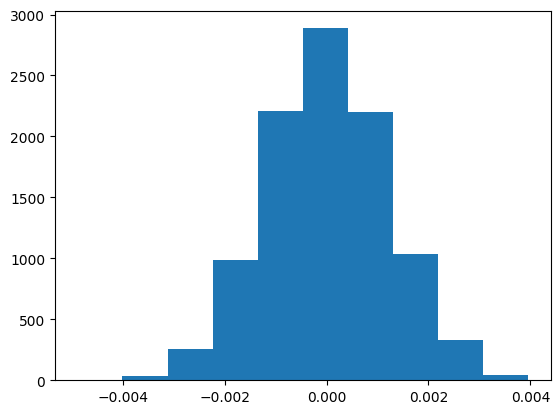

In [28]:
p_diffs = np.array(p_diffs)

plt.hist(p_diffs);

In [29]:
obs_diffs = control - treatment
obs_diffs

np.float64(0.0015782389853555567)

In [30]:
null_vals = np.random.normal(0, p_diffs.std(), p_diffs.size)

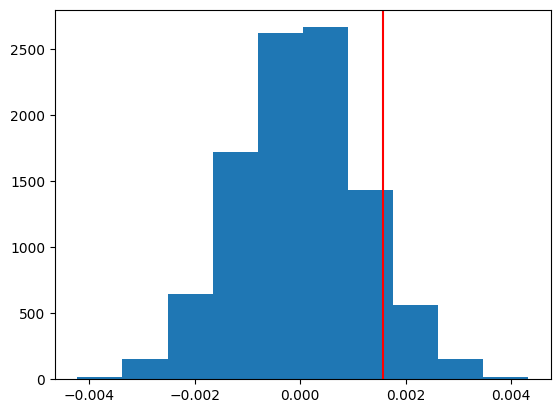

In [31]:
plt.hist(null_vals);


plt.axvline(obs_diffs, c = 'red');

In [32]:
(null_vals > obs_diffs).mean()

np.float64(0.0946)

The p-value is 9.6%, higher than Type I error which is 5%; therefore, we should fail to reject the null (H0). Besides, we can tell that actual p-value of control group is higher than than the treatment group during the calculation.
In other words, the old verison has higher p-value than the new one, so we keep the old version and do not change to the new version. Also, there is no difference between the new and old pages.

In [33]:
import statsmodels.api as sm

convert_old = old_page_converted.mean()
convert_new = new_page_converted.mean()

n_old = n_old
n_new = n_new

In [34]:
z_score, p_value = sm.stats.proportions_ztest(np.array([convert_new,convert_old]),np.array([n_new,n_old]), alternative = 'larger')
z_score, p_value

(np.float64(-0.0013037976777033689), np.float64(0.5005201398713618))

In [35]:
from scipy.stats import norm

In [36]:
norm.cdf(z_score)

np.float64(0.4994798601286382)

In [37]:
norm.ppf(1-(0.05/2))

np.float64(1.959963984540054)

The z-score does not exceed the critical value which is around 1.96; therefore, we fail to reject the null (H0).
Also, the p-value is around 50% which is not significant.
The results are all the same with the findings in parts j. and k. In other words, there is no difference between the new and old pages and we keep the old version and do not change to the new version.

# Part 3 Logistic Regression

In [38]:
df2['intercept'] = 1

df2 = df2.join(pd.get_dummies(df2['landing_page']))
df2['ab_page'] = pd.get_dummies(df2['group']) ['treatment']

In [39]:
df2.head()

,user_id,timestamp,group,landing_page,converted,intercept,new_page,old_page,ab_page
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,1,False,True,False
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,1,False,True,False
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,1,True,False,True
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,1,True,False,True
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,1,False,True,False


In [40]:
logit = sm.Logit(df2['converted'], df2[['intercept','ab_page']])

In [41]:
results = logit.fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.366118
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290582
Method:                           MLE   Df Model:                            1
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:               8.077e-06
Time:                        16:55:46   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1899
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -1.9888      0.008   -246.669      0.000      -2.005      -1.973
ab_page       -0.0150      0.011     -1.311      0.190      -0.037       0.007
==============================================================================
"""

1.The p-value associated with 'ab_page' is 0.19. Obviously, it is different from the value in Part II. The reason is because here we want to know 'ab_page' this attribute is significant or not and it is not significant in this case.

2.The null is that there is no difference between the treatment and control group. The alternative is that there is difference between the treatment and control group.

3.The result will be stronger and more convincing with new variables added into the regression model such as 'timestamp'. Moreover, the result will be stronger and more convincing with new variables added such as 'timestamp'. More specifically, I can classify this factor into 'morning', 'afternoon' and 'evening'.

4.Also I can classify them as 'weekday' and 'weekend' for better performance.
On the other hand, it will make regression model more complex and I need to check it to see if variables are dependable with each others. If yes, I need to add higher order term to get the better prediction results. Otherwise, the results should be trustworthy.

modelling with countries data

In [42]:
countries_df = pd.read_csv('./countries.csv')
df_new = countries_df.set_index('user_id').join(df2.set_index('user_id'), how='inner')

In [43]:
df_new.head()

,country,timestamp,group,landing_page,converted,intercept,new_page,old_page,ab_page
user_id,,,,,,,,,
834778,UK,2017-01-14 23:08:43.304998,control,old_page,0,1,False,True,False
928468,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,True,False,True
822059,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,True,False,True
711597,UK,2017-01-22 03:14:24.763511,control,old_page,0,1,False,True,False
710616,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,True,False,True


In [44]:
df_new.country.value_counts()

,count
country,
US,203619
UK,72466
CA,14499


In [45]:
df_new[['CA','UK','US']] = pd.get_dummies(df_new['country'])
df_new = df_new.drop(['CA'], axis =1)

In [46]:
df_new.head()

,country,timestamp,group,landing_page,converted,intercept,new_page,old_page,ab_page,UK,US
user_id,,,,,,,,,,,
834778,UK,2017-01-14 23:08:43.304998,control,old_page,0,1,False,True,False,True,False
928468,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,True,False,True,False,True
822059,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,True,False,True,True,False
711597,UK,2017-01-22 03:14:24.763511,control,old_page,0,1,False,True,False,True,False
710616,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,True,False,True,True,False


In [47]:
df_new['intercept'] = 1

logit2 = sm.Logit(df_new['converted'], df_new[['intercept','new_page','UK','US']])
result = logit2.fit()
result.summary()

Optimization terminated successfully.
         Current function value: 0.366113
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290580
Method:                           MLE   Df Model:                            3
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:               2.323e-05
Time:                        16:59:37   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1760
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -2.0300      0.027    -76.249      0.000      -2.082      -1.978
new_page      -0.0149      0.011     -1.307      0.191      -0.037       0.007
UK             0.0506      0.028      1.784      0.074      -0.005       0.106
US             0.0408      0.027      1.516      0.130      -0.012       0.093
==============================================================================
"""

In [48]:
1/np.exp(-0.0149),np.exp(0.0506),np.exp(0.0408)

(np.float64(1.0150115583846535),
 np.float64(1.0519020483004984),
 np.float64(1.0416437559600236))

In [49]:
df_new['UK_new_page'] = df_new['new_page']* df_new['UK']
df_new['US_new_page'] = df_new['new_page']* df_new['US']

In [50]:
df_new.head()

,country,timestamp,group,landing_page,converted,intercept,new_page,old_page,ab_page,UK,US,UK_new_page,US_new_page
user_id,,,,,,,,,,,,,
834778,UK,2017-01-14 23:08:43.304998,control,old_page,0,1,False,True,False,True,False,False,False
928468,US,2017-01-23 14:44:16.387854,treatment,new_page,0,1,True,False,True,False,True,False,True
822059,UK,2017-01-16 14:04:14.719771,treatment,new_page,1,1,True,False,True,True,False,True,False
711597,UK,2017-01-22 03:14:24.763511,control,old_page,0,1,False,True,False,True,False,False,False
710616,UK,2017-01-16 13:14:44.000513,treatment,new_page,0,1,True,False,True,True,False,True,False


In [51]:
logit3 = sm.Logit(df_new['converted'], df_new[['intercept','new_page','UK_new_page','US_new_page','UK','US']])
result = logit3.fit()
result.summary()

Optimization terminated successfully.
         Current function value: 0.366109
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290578
Method:                           MLE   Df Model:                            5
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:               3.482e-05
Time:                        17:00:31   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1920
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept      -2.0040      0.036    -55.008      0.000      -2.075      -1.933
new_page       -0.0674      0.052     -1.297      0.195      -0.169       0.034
UK_new_page     0.0783      0.057      1.378      0.168      -0.033       0.190
US_new_page     0.0469      0.054      0.872      0.383      -0.059       0.152
UK              0.0118      0.040      0.296      0.767      -0.066       0.090
US              0.0175      0.038      0.465      0.642      -0.056       0.091
===============================================================================
"""

In [52]:
1/np.exp(-0.0674),np.exp(0.0783),np.exp(0.0469),np.exp(0.0118),np.exp(0.0175)

(np.float64(1.0697232819209153),
 np.float64(1.0814470441230692),
 np.float64(1.048017202119183),
 np.float64(1.011869894648401),
 np.float64(1.0176540221507617))

From above, we can tell that except the p-value of 'intercept' is less than TypeI error = 5%, other variables are exceed TypeI error = 5% which means they are not significant. In addition, their z-scores are not large enough which means they are not significant as well.

However, we still can tell that when 'new_page' decreases one unit, the converted will increase 7%.
When 'UK_new_page' increases one unit, the converted will increase 8.1%.

When 'US_new_page' increases one unit, the converted will increase 4.8%.

When 'UK' increases one unit, the converted will increase 1.2%.

When 'US' increases one unit, the converted will increase 1.8%.